## **Trouver des entreprises et agences spécialisées en IA à Marrakech**

**Question métier :**
Nous souhaitons analyser l’écosystème des entreprises et agences liées à l’intelligence artificielle à Marrakech afin d’identifier les acteurs présents sur le marché, leurs secteurs d’activité, leur localisation, leur présence numérique et les opportunités potentielles.

**Imporatation**

In [1]:
import requests
import pandas as pd
import time
import os
from datetime import datetime, timedelta

### Google Maps access token

In [2]:
#from google.colab import userdata
from dotenv import load_dotenv

load_dotenv(dotenv_path=".env")

API_KEY = os.getenv("GOOGLE_MAPS_API_KEY")

if API_KEY is None:
    raise ValueError(
        "La clé GOOGLE_MAPS_API_KEY est absente."
    )

print("Clé API chargée avec succès.")

Clé API chargée avec succès.


### Google Places API base URL

In [3]:
url = "https://places.googleapis.com/v1/places:searchText"

Cette URL correspond à l'endpoint Text Search.

Préparer les headers

In [4]:
headers = {
        "Content-Type": "application/json",
        "X-Goog-Api-Key": API_KEY,
        "X-Goog-FieldMask": (
            "places.id,"
            "places.displayName,"
            "places.formattedAddress,"
            "places.location,"
            "places.rating,"
            "places.userRatingCount,"
            "places.websiteUri,"
            "places.nationalPhoneNumber,"
            "places.primaryType"
        )
    }

In [5]:
query = "entreprises intelligence artificielle Data analysis agency Marrakech"

In [6]:
data = {
        "textQuery": query,
        "languageCode": "fr",
        "regionCode": "MA",
        "pageSize": 20
    }

Envoyer la requête

In [7]:
response = requests.post(url,headers=headers,json=data)

In [8]:
if response.status_code != 200:
    print(response.text)

print("Status :", response.status_code)

Status : 200


Récupérer le JSON

In [9]:
result = response.json()
result

{'places': [{'id': 'ChIJwWQgn3bvrw0Rd4BO-FsEmhU',
   'nationalPhoneNumber': '06 43 73 01 58',
   'formattedAddress': 'Marrakech 40000',
   'location': {'latitude': 31.633837999999997, 'longitude': -7.9852459},
   'displayName': {'text': 'Artificial.ma - Agence Intelligence Artificielle',
    'languageCode': 'en'},
   'primaryType': 'service'},
  {'id': 'ChIJ5f2YkYHurw0RulY6j2k_VFs',
   'nationalPhoneNumber': '06 66 77 80 23',
   'formattedAddress': 'Bureau 18، 5ème étage، Centre d’affaires Bergis، 3 Avenue SAFI، Marrakech 40090',
   'location': {'latitude': 31.646523600000002, 'longitude': -8.0112468},
   'rating': 4.9,
   'websiteUri': 'https://www.monarkit.net/',
   'userRatingCount': 103,
   'displayName': {'text': 'MONARK IT', 'languageCode': 'fr'},
   'primaryType': 'service'},
  {'id': 'ChIJnUvH9aztrw0RYLenJy-32tQ',
   'nationalPhoneNumber': '06 80 79 25 42',
   'formattedAddress': 'Burj Malak, 2ème étage, bureau N°27, Immeuble Burj Malak, Rte de Safi, Marrakech 40000',
   'locat

In [10]:
#import json
#print(json.dumps(result,indent=2,ensure_ascii=False))

Récupérer les entreprises

In [11]:
places = result.get("places", [])
print("Nombre de résultats :", len(places))

Nombre de résultats : 5


In [12]:
for place in places:
    print(place.get("displayName", {}).get("text"))

Artificial.ma - Agence Intelligence Artificielle
MONARK IT
POWABU | Agence IA & Automatisation
IT Labs Pro, Agence web au Maroc
N.Synergy Bureau d'Étude Technique, Développement web


Transformer les données en tableau

In [13]:
data_list = []

for place in places:

  location = place.get("location", {})
  display_name = place.get("displayName", {})

  data_list.append({
      "place_id": place.get("id"),
      "name": display_name.get("text"),
      "address": place.get("formattedAddress"),
      "phone": place.get("nationalPhoneNumber"),
      "website": place.get("websiteUri"),
      "rating": place.get("rating"),
      "reviews": place.get("userRatingCount"),
      "latitude": location.get("latitude"),
      "longitude": location.get("longitude"),
      "category": place.get("primaryType"),
      "search_query": query
    })

In [14]:
df_ia=pd.DataFrame(data_list)
df_ia

,place_id,name,address,phone,website,rating,reviews,latitude,longitude,category,search_query
0,ChIJwWQgn3bvrw0Rd4BO-FsEmhU,Artificial.ma - Agence Intelligence Artificielle,Marrakech 40000,06 43 73 01 58,NaN,NaN,NaN,31.633838,-7.985246,service,entreprises intelligence artificielle Data ana...
1,ChIJ5f2YkYHurw0RulY6j2k_VFs,MONARK IT,Bureau 18، 5ème étage، Centre d’affaires Bergi...,06 66 77 80 23,https://www.monarkit.net/,4.9,103.0,31.646524,-8.011247,service,entreprises intelligence artificielle Data ana...
2,ChIJnUvH9aztrw0RYLenJy-32tQ,POWABU | Agence IA & Automatisation,"Burj Malak, 2ème étage, bureau N°27, Immeuble ...",06 80 79 25 42,https://powabu.ma/agence-ia-marrakech/,5.0,5.0,31.664444,-8.032791,service,entreprises intelligence artificielle Data ana...
3,ChIJM6HCJLLurw0RNXtfCsM5iQM,"IT Labs Pro, Agence web au Maroc","74, Imm Elizabeth, N°15 Av. Hassan II, Marrake...",05 24 44 78 44,https://www.itlabspro.com/,5.0,31.0,31.633213,-8.004205,service,entreprises intelligence artificielle Data ana...
4,ChIJVajYK0zvrw0RfP9VAvAMulA,"N.Synergy Bureau d'Étude Technique, Développem...","4eme Etage N° 17, Centre d'affaires JOUDAD, N9...",06 88 21 22 23,https://www.nsynergy.ma/,4.6,7.0,31.656433,-8.017697,consultant,entreprises intelligence artificielle Data ana...


In [15]:
print("Nombre de lignes :", df_ia.shape[0])
print("Nombre de colonnes :", df_ia.shape[1])

Nombre de lignes : 5
Nombre de colonnes : 11


In [16]:
print("Nombre de lignes :", df_ia.shape[0])
print("Nombre de colonnes :", df_ia.shape[1])

Nombre de lignes : 5
Nombre de colonnes : 11


In [17]:
df_ia.columns

Index(['place_id', 'name', 'address', 'phone', 'website', 'rating', 'reviews',
       'latitude', 'longitude', 'category', 'search_query'],
      dtype='str')

In [18]:
print("Nombre d'entreprises :", len(df_ia))

Nombre d'entreprises : 5


Faire plusieurs recherches

In [19]:
queries = [
    "AI solutions Marrakech",
    "Artificial Intelligence services Marrakech",
    "AI technology Marrakech",
    "Machine Learning services Marrakech",
    "Data Science Marrakech",
    "Data Analytics Marrakech",
    "Business Intelligence Marrakech",
    "Big Data Marrakech",
    "Data consulting Marrakech",
    "Digital transformation Marrakech",
    "IT consulting Marrakech",
    "Technology consulting Marrakech",
    "Software development Marrakech",
    "Web development companies Marrakech",
    "Tech companies Marrakech",
    "Innovation companies Marrakech",
    "Technology startups Marrakech",
    "Fintech Marrakech",
    "SaaS companies Marrakech",
    "Cloud computing Marrakech",
    "Cybersecurity companies Marrakech",
    "ERP companies Marrakech",
    "CRM companies Marrakech",
    "Marketing technology Marrakech",
    "Digital marketing agencies Marrakech"
]

In [20]:
def search_places(query):

    url = "https://places.googleapis.com/v1/places:searchText"

    headers = {
        "Content-Type": "application/json",
        "X-Goog-Api-Key": API_KEY,
        "X-Goog-FieldMask": (
            "places.id,"
            "places.displayName,"
            "places.formattedAddress,"
            "places.location,"
            "places.googleMapsUri,"
            "places.websiteUri,"
            "places.nationalPhoneNumber,"
            "places.rating,"
            "places.userRatingCount,"
            "places.primaryTypeDisplayName"
        )
    }

    data = {
        "textQuery": query,
        "languageCode": "fr"
    }

    response = requests.post(
        url,
        headers=headers,
        json=data,
        timeout=30
    )

    if response.status_code != 200:
        print("Erreur :", response.status_code)
        print(response.text)
        return []

    return response.json().get("places", [])

In [21]:
all_places = []

for query in queries:

    print("Recherche :", query)

    places = search_places(query)

    for place in places:

        all_places.append({
            "query": query,
            "place_id": place.get("id"),

            "nom": place.get(
                "displayName", {}
            ).get("text"),

            "adresse": place.get(
                "formattedAddress"
            ),

            "telephone": place.get(
                "nationalPhoneNumber"
            ),

            "site_web": place.get(
                "websiteUri"
            ),

            "google_maps": place.get(
                "googleMapsUri"
            ),

            "note": place.get(
                "rating"
            ),

            "nombre_avis": place.get(
                "userRatingCount"
            ),

            "categorie": place.get(
                "primaryTypeDisplayName", {}
            ).get("text"),

            "latitude": place.get(
                "location", {}
            ).get("latitude"),

            "longitude": place.get(
                "location", {}
            ).get("longitude")
        })

Recherche : AI solutions Marrakech
Recherche : Artificial Intelligence services Marrakech
Recherche : AI technology Marrakech
Recherche : Machine Learning services Marrakech
Recherche : Data Science Marrakech
Recherche : Data Analytics Marrakech
Recherche : Business Intelligence Marrakech
Recherche : Big Data Marrakech
Recherche : Data consulting Marrakech
Recherche : Digital transformation Marrakech
Recherche : IT consulting Marrakech
Recherche : Technology consulting Marrakech
Recherche : Software development Marrakech
Recherche : Web development companies Marrakech
Recherche : Tech companies Marrakech
Recherche : Innovation companies Marrakech
Recherche : Technology startups Marrakech
Recherche : Fintech Marrakech
Recherche : SaaS companies Marrakech
Recherche : Cloud computing Marrakech
Recherche : Cybersecurity companies Marrakech
Recherche : ERP companies Marrakech
Recherche : CRM companies Marrakech
Recherche : Marketing technology Marrakech
Recherche : Digital marketing agencie

In [22]:
df = pd.DataFrame(all_places)

df.head()

,query,place_id,nom,adresse,telephone,site_web,google_maps,note,nombre_avis,categorie,latitude,longitude
0,AI solutions Marrakech,ChIJi2wiLAXvrw0Rf8bk3bI2RrE,Autosolve AI,"APPT 15 IMM 12, LOT SINE Bd Allal Al Fassi, Ma...",NaN,https://www.autosolve-ai.com/,https://maps.google.com/?cid=12773957534937826...,5.0,1.0,Services,31.644108,-8.000206
1,Artificial Intelligence services Marrakech,ChIJwWQgn3bvrw0Rd4BO-FsEmhU,Artificial.ma - Agence Intelligence Artificielle,"Marrakech 40000, Maroc",06 43 73 01 58,NaN,https://maps.google.com/?cid=15565614142643569...,NaN,NaN,Services,31.633838,-7.985246
2,AI technology Marrakech,ChIJpSDiSyzrrw0RBTQM-GbL8zA,Spark Tech by Aitela,"597 ALMASSAR QI, Marrakech 40150, Maroc",07 08 22 64 81,https://www.hellospark.tech/,https://maps.google.com/?cid=35273865762698823...,4.0,5.0,Services,31.672369,-8.039186
3,AI technology Marrakech,ChIJFwNchpftrw0RzcwDx1d6ngg,A5 Technology,"2, N160 Rte de Safi, Marrakech 40160, Maroc",07 08 68 86 80,https://www.a5-technology.com/,https://maps.google.com/?cid=62106831604336558...,5.0,1.0,NaN,31.673319,-8.034484
4,AI technology Marrakech,ChIJCzCONI3trw0RtLiA4sXXls4,AIR TECHNOLOGY,"ZI, Marrakech 40000, Maroc",06 61 14 42 16,NaN,https://maps.google.com/?cid=14886322863228369...,5.0,3.0,Magasin,31.669204,-8.045727


In [23]:
print("Nombre d'entreprises :", len(df))

Nombre d'entreprises : 265


<h1 align="center"> Nettoyage des données </h1>

1. Vérifier les doublons

In [24]:
df.duplicated(subset="place_id").sum()


np.int64(99)

2. Supprimer les doublons

In [25]:
df = df.drop_duplicates(subset="place_id").copy()
print("Nombre d'entreprises après suppression des doublons :", len(df))


Nombre d'entreprises après suppression des doublons : 166


3. Vérifier les valeurs manquantes

In [26]:
df.isnull().sum()


query           0
place_id        0
nom             0
adresse         0
telephone       8
site_web       22
google_maps     0
note           16
nombre_avis    16
categorie       7
latitude        0
longitude       0
dtype: int64

4. Supprimer les lignes incomplètes (place_id ou nom manquants)

In [27]:
df = df.dropna(subset=["place_id", "nom"]).copy()
print("Nombre d'entreprises après suppression des lignes incomplètes :", len(df))


Nombre d'entreprises après suppression des lignes incomplètes : 166


5. Sélectionner les colonnes utiles

In [28]:
df_marrakech = df[
    [
        "place_id",
        "nom",
        "adresse",
        "telephone",
        "site_web",
        "google_maps",
        "categorie",
        "note",
        "nombre_avis",
        "latitude",
        "longitude"
    ]
].copy()


6. Nettoyer les noms

In [29]:
df_marrakech["nom"] = (
    df_marrakech["nom"]
    .astype("string")
    .str.strip()
)


7. Nettoyer les adresses

In [30]:
df_marrakech["adresse"] = (
    df_marrakech["adresse"]
    .astype("string")
    .str.strip()
)


8. Nettoyer le site web et le numéro de téléphone

In [31]:
for col in ["site_web", "telephone", "categorie", "google_maps"]:
    if col in df_marrakech.columns:
        df_marrakech[col] = df_marrakech[col].astype("string").str.strip()


9. Nettoyer les colonnes numériques

In [32]:
for col in ["note", "nombre_avis", "latitude", "longitude"]:
    df_marrakech[col] = pd.to_numeric(df_marrakech[col], errors="coerce")


10. Vérifier les types après nettoyage

In [33]:
df_marrakech.dtypes


place_id           str
nom             string
adresse         string
telephone       string
site_web        string
google_maps     string
categorie       string
note           float64
nombre_avis    float64
latitude       float64
longitude      float64
dtype: object

11. Vérifier que les entreprises sont bien à Marrakech

In [34]:
# Une entreprise est conservée seulement si "Marrakech" apparaît dans son adresse
mask_marrakech = (
    df_marrakech["adresse"]
    .str.contains("Marrakech", case=False, na=False)
)
print("Entreprises hors Marrakech détectées :", (~mask_marrakech).sum())
df_marrakech = df_marrakech[mask_marrakech].copy()
print("Entreprises conservées :", len(df_marrakech))


Entreprises hors Marrakech détectées : 26
Entreprises conservées : 140


12. Vérifier la cohérence des notes et coordonnées

In [35]:
# La note Google va normalement de 0 à 5 ; les coordonnées de Marrakech sont autour de
# lat ~31.6, lon ~ -8.0. On repère les valeurs suspectes sans les supprimer automatiquement.
notes_invalides = df_marrakech[(df_marrakech["note"] < 0) | (df_marrakech["note"] > 5)]
coord_manquantes = df_marrakech[df_marrakech[["latitude", "longitude"]].isnull().any(axis=1)]
print("Notes hors intervalle [0,5] :", len(notes_invalides))
print("Entreprises sans coordonnées :", len(coord_manquantes))


Notes hors intervalle [0,5] : 0
Entreprises sans coordonnées : 0


13. Réinitialiser l'index après nettoyage

In [36]:
df_marrakech = df_marrakech.reset_index(drop=True)


14. Résumé avant / après nettoyage

In [37]:
print("Valeurs manquantes restantes :")
print(df_marrakech.isnull().sum())
print()
print("Doublons restants (place_id) :", df_marrakech.duplicated(subset="place_id").sum())
print("Nombre final d'entreprises après nettoyage :", len(df_marrakech))
df_marrakech.head(20)


Valeurs manquantes restantes :
place_id        0
nom             0
adresse         0
telephone       6
site_web       19
google_maps     0
categorie       7
note           16
nombre_avis    16
latitude        0
longitude       0
dtype: int64

Doublons restants (place_id) : 0
Nombre final d'entreprises après nettoyage : 140


,place_id,nom,adresse,telephone,site_web,google_maps,categorie,note,nombre_avis,latitude,longitude
0,ChIJi2wiLAXvrw0Rf8bk3bI2RrE,Autosolve AI,"APPT 15 IMM 12, LOT SINE Bd Allal Al Fassi, Ma...",<NA>,https://www.autosolve-ai.com/,https://maps.google.com/?cid=12773957534937826...,Services,5.0,1.0,31.644108,-8.000206
1,ChIJwWQgn3bvrw0Rd4BO-FsEmhU,Artificial.ma - Agence Intelligence Artificielle,"Marrakech 40000, Maroc",06 43 73 01 58,<NA>,https://maps.google.com/?cid=15565614142643569...,Services,NaN,NaN,31.633838,-7.985246
2,ChIJpSDiSyzrrw0RBTQM-GbL8zA,Spark Tech by Aitela,"597 ALMASSAR QI, Marrakech 40150, Maroc",07 08 22 64 81,https://www.hellospark.tech/,https://maps.google.com/?cid=35273865762698823...,Services,4.0,5.0,31.672369,-8.039186
3,ChIJFwNchpftrw0RzcwDx1d6ngg,A5 Technology,"2, N160 Rte de Safi, Marrakech 40160, Maroc",07 08 68 86 80,https://www.a5-technology.com/,https://maps.google.com/?cid=62106831604336558...,<NA>,5.0,1.0,31.673319,-8.034484
4,ChIJCzCONI3trw0RtLiA4sXXls4,AIR TECHNOLOGY,"ZI, Marrakech 40000, Maroc",06 61 14 42 16,<NA>,https://maps.google.com/?cid=14886322863228369...,Magasin,5.0,3.0,31.669204,-8.045727
5,ChIJV5mXQqbprw0Rb9bUZjP3cqI,ZG Technology,Magasin RDC lotissement errahan N10-13 M'hamid...,06 04 82 67 59,https://zgtechnology.ma/,https://maps.google.com/?cid=11705690181629957...,Services,5.0,10.0,31.583910,-8.048459
6,ChIJd7NRRQDprw0RC0jxu6SmlWY,Mougha Tech,"40160, Marrakech 40140, Maroc",07 70 73 90 37,http://moughatech.net/,https://maps.google.com/?cid=73919975898565365...,Magasin d'électronique,5.0,16.0,31.586252,-8.023768
7,ChIJCb8hWNbprw0Rxn5QqZCyPBM,"DestockAfric - Matériel Informatique, PC & Imp...","Operation baht, magasin n1, Marrakech 40140, M...",07 02 05 95 96,http://www.destockafric.com/,https://maps.google.com/?cid=13861791197089297...,Magasin d'électronique,4.8,298.0,31.631282,-8.058527
8,ChIJM6HCJLLurw0RNXtfCsM5iQM,"IT Labs Pro, Agence web au Maroc","74, Imm Elizabeth, N°15 Av. Hassan II, Marrake...",05 24 44 78 44,https://www.itlabspro.com/,https://maps.google.com/?cid=25479836377857925...,Services,5.0,31.0,31.633213,-8.004205
9,ChIJ-cVfOZrvrw0RkpMs-E2-nPw,Algorithmics School Marrakech - Gueliz,"4eme Étage, N15, Centre d'affaires Bergis, Av ...",06 63 25 68 58,https://gueliz.alg.academy/,https://maps.google.com/?cid=18202633036010132...,Établissement d'enseignement,5.0,28.0,31.646470,-8.011485


Export CSV et Excel

In [38]:
df_marrakech.to_csv(
    "entreprises_IA_Marrakech.csv",
    index=False,
    encoding="utf-8-sig"
)


In [39]:
df_marrakech.to_excel(
    "entreprises_IA_Marrakech.xlsx",
    index=False
)


In [40]:
from matplotlib import pyplot as plt

In [41]:
#df_marrakech["categorie"].value_counts().plot(
  #  kind="bar")

#plt.title(
 #   "Entreprises / agences liées à l'IA à Marrakech")

#plt.xlabel("Catégorie")
#plt.ylabel("Nombre")

#plt.xticks(rotation=45)
#plt.tight_layout()
#plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_10356\150366223.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


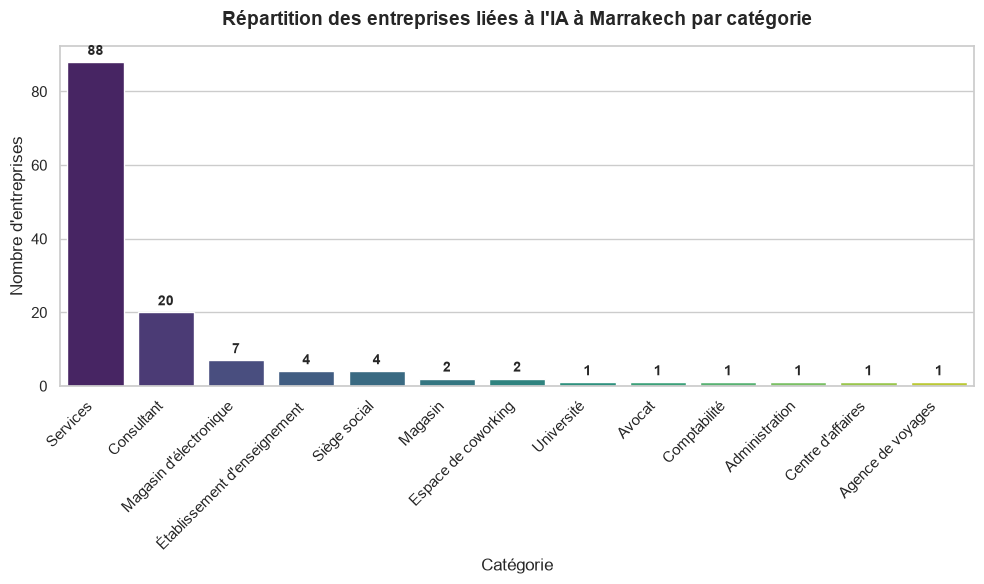

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style graphique
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Calcul du nombre d'entreprises par catégorie
cat_counts = df_marrakech['categorie'].value_counts()

# Création du barplot
ax = sns.barplot(
    x=cat_counts.index,
    y=cat_counts.values,
    palette="viridis"
)

# Ajout des labels et titres
plt.title("Répartition des entreprises liées à l'IA à Marrakech par catégorie", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Catégorie", fontsize=12)
plt.ylabel("Nombre d'entreprises", fontsize=12)
plt.xticks(rotation=45, ha='right')

# Affichage des valeurs exactes sur chaque barre
for bar in ax.patches:
    height = bar.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height)}',
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold'
        )

plt.tight_layout()
plt.show()